# E1 Measurement of magnitudes

## Introduction

We will cover the basics of measurement of typical magnitudes important in the performance of an axial fan. An example of performance measurement
of a centrifugal fan is revised. 

## Learning Objectives

- Learn the basics about pressure measurement
- Learn the basics about temperature measurement
- Learn the basics about velocity and flow rate measurement
- Learn the basics about torque measurement
- Learn the basics about rotational velocity measurement
- Perform flow rate, head, power consumption and efficiency computation from raw measurements of basic magnitudes in the flow and the machine 

## Previous tasks (about 2 hours)

For the book by Dick

Dick, Erik. Fundamentals of Turbomachines. Vol. 109. Dordrecht, The Netherlands: Springer, 2015.

which is [available in the UPC library](https://link-springer-com.recursos.biblioteca.upc.edu/book/10.1007/978-3-030-93578-8)


 - Read sections 5.1-5.5

## Some simple questions

For the typical value of pressure rise in an axial fan, what is the most suitable type of pressure measurement equipment? If it has to be calibrated with a U tube with water, what is the typical height difference expected?

Answer:

The most suitable type of pressure measurement equipment is Digital Micromanometer. Expected height difference between 10 mm to 50 mm for standard ventilation fans.
***

What kind of flow measurement device is more convenient for air flow rate in an axial fan? What does it mean that the flow has to be _fully developed_ and why is that so important?

Answer:

According to Sections 5.3.3 and 5.3.5, the most convenient device for measuring air flow rate in an axial fan setup is a pressure drop device, specifically an inlet nozzle mounted at the duct entry. As defined in Section 5.3.5, a fully developed flow is one with "a velocity profile that does not change in the flow direction."
***

What kind of torque measurement device would you use for an axial fan and why?

Answer:

The appropriate torque measurement method is a calibrated motor (Section 5.4.2) because it is a compact, direct-drive unit with an integrated motor where the impeller is mounted directly onto the motor shaft.
***

What kind of rotational velocity  measurement device would you use for an axial fan and why?

Answer:

The best rotational velocity measurement device for an axial fan is a non-contact optical tachometer (specifically a handheld laser tachometer with a reflective strip) for general testing and compact fans, or a rotational speed transducer (Hall-effect or magnetic-inductive sensor) for permanent, continuous monitoring.

***

## Tasks

This task is adapted from section 5.7 in the book by Dick

The objective is to draw the **performance curve** ($Y = \frac{\Delta p_0}{\rho}$, $P$ and $\eta$ versus $Q$) for a given rotational velocity of a **centrifugal fan**.

The test rig is sketched in this figure

![test_rig](images/E1_test_rig_fan.png)

The rotational velocity of the driving motor of the fan is not constant, but function of the consumed power. The torque produced by the motor and the
rotational velocity can be approximated as a **linear function** of the consumed power. It is measured that for a torque of $M = 0 \,\text{N\,m}$ electric power is
$P_e = 165\,\text{W}$ and for $M = 12\,\text{N\,m}$ it is $P_e = 4225\,\text{W}$. Likewise, for a rotational velocity $N = 2750\,\text{rpm}$ consumed power is 
$P_e = 400\,\text{W}$ and for $N = 2630\,\text{rpm}$ it is $P_e = 3620\,\text{W}$. Ambient pressure and temperatures are $P_a = 100.4\,\text{kPa}$ and $T_a = 21.0 \, \text{°C}$.

The nozzle flow meter is a standard design type ISA 1932, according to [ISO-5167](https://plataforma-aenormas-aenor-com.recursos.biblioteca.upc.edu/standard/UNE/N0071852), with $D = 182.9\,\text{mm}$ and $d = 114.0\,\text{mm}$.


For a given cone control position, consumed power ($P_e$) in $\text{W}$, temperature ($T$) in Celsius degrees, pressure ($p$) at fan outlet, pressures at nozzle inlet ($p_1$) and pressure difference
in nozzle ($\Delta p = p_2 - p_1$) in $\text{kPa}$ are measured. The data are that stored in pandas data frame `exp_data`

In [16]:
import pandas as pd
import numpy as np

pd.set_option('display.float_format', '{:.4g}'.format) # To limit to 4 the number of significant digits in the output

P_e = np.array([1200, 1480, 1840, 2240, 2640, 3000, 3400, 3760]) # Power in watts
T = np.array([27.4, 25.7, 24.6, 24.0, 23.7, 23.6, 23.2, 22.5]) # Temperature in degrees Celsius
p = np.array([2.92, 3.06, 3.13, 3.13, 3.08, 2.92, 2.60, 2.23]) # Pressure in kPa, measured at the outlet of the system
p1 = np.array([2.92, 3.04, 3.09, 3.06, 2.96, 2.76, 2.38, 1.95]) # Pressure in kPa, measured at the inlet of the nozzle flow meter
Delta_p = np.array([0.0, 0.07, 0.27, 0.60, 1.05, 1.60, 2.38, 3.25]) # Pressure drop in kPa in nozzle flow meter (p2 - p1)
exp_data = pd.DataFrame({
    'P_e (W)': P_e,
    'T (°C)': T,
    'p (kPa)': p,
    'p1 (kPa)': p1,
    'Delta_p (kPa)': Delta_p
})
exp_data # to display the experimental data in a tabular format

,P_e (W),T (°C),p (kPa),p1 (kPa),Delta_p (kPa)
0,1200,27.4,2.92,2.92,0
1,1480,25.7,3.06,3.04,0.07
2,1840,24.6,3.13,3.09,0.27
3,2240,24,3.13,3.06,0.6
4,2640,23.7,3.08,2.96,1.05
5,3000,23.6,2.92,2.76,1.6
6,3400,23.2,2.6,2.38,2.38
7,3760,22.5,2.23,1.95,3.25


1. Compute actual rotational velocity in $\text{rpm}$ and torque in $\text{N\,m}$ from above lineal correlation. It can be done directly in the pandas dataframe with an expression of the type `exp_data['N (rpm)'] = (N2-N1)/(Pe_2_N-Pe_1_N)*(exp_data['P_e (W)'] -Pe_1_N) + N1`.

In [17]:
N2 = 2630
N1 = 2750
Pe_2_N = 3620
Pe_1_N = 400
exp_data['N (rpm)'] = (N2-N1) * (exp_data['P_e (W)'] - Pe_1_N) / (Pe_2_N - Pe_1_N) + N1
M2 = 12
M1 = 0
Pe_2_M = 4225
Pe_1_M = 165
exp_data['M (N m)'] = (M2-M1) * (exp_data['P_e (W)'] - Pe_1_M) / (Pe_2_M - Pe_1_M) + M1
exp_data

,P_e (W),T (°C),p (kPa),p1 (kPa),Delta_p (kPa),N (rpm),M (N m)
0,1200,27.4,2.92,2.92,0,2720,3.059
1,1480,25.7,3.06,3.04,0.07,2710,3.887
2,1840,24.6,3.13,3.09,0.27,2696,4.951
3,2240,24,3.13,3.06,0.6,2681,6.133
4,2640,23.7,3.08,2.96,1.05,2667,7.315
5,3000,23.6,2.92,2.76,1.6,2653,8.379
6,3400,23.2,2.6,2.38,2.38,2638,9.562
7,3760,22.5,2.23,1.95,3.25,2625,10.63


2. We are going to need density of gas in the flow meter nozzle in order to compute mass flow rate, at point 1. It can be done by using ideal gas equation, and assuming that $T_1 \approx T$. Create a column in the dataframe with the density at point 1, $\rho_1 (\text{kg/m}^3)$,
$$
\rho_1 = \frac{p_1}{R T}
$$
where $ R = 287.05\,\text{J/(kg\,K)}$ and $p$ and $T$ are **absolute** pressure and temperature.

Define also ambient pressure, temperature and density, that may be used later.

In [18]:
# Gas constant and ambient conditions (in SI base units: Pa, K, kg/m^3)
R = 287.05          # J/(kg·K)
P_a = 100.4 * 1e3   # Ambient pressure in Pa (100.4 kPa)
T_a = 21.0 + 273.15 # Ambient temperature in K (21.0 °C)
rho_a = P_a / (R * T_a) # Ambient air density in kg/m^3

# Compute absolute pressure (Pa) and absolute temperature (K) at nozzle inlet (point 1)
p1_abs = P_a + exp_data['p1 (kPa)'] * 1e3
T_abs = exp_data['T (°C)'] + 273.15

# Add density column to the DataFrame
exp_data['rho_1 (kg/m^3)'] = p1_abs / (R * T_abs)

print(f"Ambient density (rho_a): {rho_a:.4g} kg/m^3")
exp_data

Ambient density (rho_a): 1.189 kg/m^3


,P_e (W),T (°C),p (kPa),p1 (kPa),Delta_p (kPa),N (rpm),M (N m),rho_1 (kg/m^3)
0,1200,27.4,2.92,2.92,0,2720,3.059,1.198
1,1480,25.7,3.06,3.04,0.07,2710,3.887,1.206
2,1840,24.6,3.13,3.09,0.27,2696,4.951,1.211
3,2240,24,3.13,3.06,0.6,2681,6.133,1.213
4,2640,23.7,3.08,2.96,1.05,2667,7.315,1.213
5,3000,23.6,2.92,2.76,1.6,2653,8.379,1.211
6,3400,23.2,2.6,2.38,2.38,2638,9.562,1.208
7,3760,22.5,2.23,1.95,3.25,2625,10.63,1.206


1. Also viscosity will be nedded to calculate Reynolds number. Define a new column with viscosity of fluid at point 1, that can be related with temperture with the expression
   $$
    \mu_1(T_1) = (17.1 + 0.048\, T_1)\times 10^{-6} \, \text{Pa s}
   $$
   where $T_1$ is expressed in Celsius degrees for $-20 °C < T_1 < 100 °C$. This is the linear correlation recommended by the [ISO 5801:2019](https://plataforma-aenormas-aenor-com.recursos.biblioteca.upc.edu/standard/UNE/N0061895).

In [19]:
# Dynamic viscosity at point 1 in Pa·s (T is directly in °C)
exp_data['mu_1 (Pa s)'] = (17.1 + 0.048 * exp_data['T (°C)']) * 1e-6

exp_data

,P_e (W),T (°C),p (kPa),p1 (kPa),Delta_p (kPa),N (rpm),M (N m),rho_1 (kg/m^3),mu_1 (Pa s)
0,1200,27.4,2.92,2.92,0,2720,3.059,1.198,1.842e-05
1,1480,25.7,3.06,3.04,0.07,2710,3.887,1.206,1.833e-05
2,1840,24.6,3.13,3.09,0.27,2696,4.951,1.211,1.828e-05
3,2240,24,3.13,3.06,0.6,2681,6.133,1.213,1.825e-05
4,2640,23.7,3.08,2.96,1.05,2667,7.315,1.213,1.824e-05
5,3000,23.6,2.92,2.76,1.6,2653,8.379,1.211,1.823e-05
6,3400,23.2,2.6,2.38,2.38,2638,9.562,1.208,1.821e-05
7,3760,22.5,2.23,1.95,3.25,2625,10.63,1.206,1.818e-05


4. Compute mass flow rate for each operation point according to ISO-5167 procedure. Since the discharge coefficient is function of the Reynolds number, which is
function of flow rate, it has to be done by iterations until convergence is reached. This can be directly done using the 
[`flow_meter`](https://fluids.readthedocs.io/fluids.flow_meter.html) module in the `fluid` 
python package

    This is an example:

    ``` python
    from fluids.flow_meter import *

    differential_pressure_meter_solver(D=0.1829, 
                                   D2=0.114,
                                   rho=1.2,
                                   mu=1.8e-5,
                                   P1 = 103000,
                                   P2 = 102500,
                                   k = 1.4,
                                   meter_type='ISA 1932 nozzle'
    )

    0.3654245417430694
    ```

    Note that this module does not accept `Series` or `arrays` as inputs (it is not vectorized), so a loop has to be coded. Also note that pressures have to be passed as absolute values. Another note, be careful with the flow rate when the pressure drop is zero in the flow meter. It is obviously zero, but if you try to compute it with the solver you will get a division by zero error because of the Reynolds number. 


In [20]:
%pip install fluids
from fluids.flow_meter import differential_pressure_meter_solver

# Nozzle geometry and gas properties
D = 0.1829   # Duct diameter in m
D2 = 0.1140  # Nozzle throat diameter in m
k = 1.4      # Adiabatic index for air

m_dot_list = []

for _, row in exp_data.iterrows():
    if row['Delta_p (kPa)'] == 0:
        m_dot_list.append(0.0)
    else:
        P1_abs = P_a + row['p1 (kPa)'] * 1e3
        P2_abs = P1_abs - row['Delta_p (kPa)'] * 1e3
        
        m_dot = differential_pressure_meter_solver(
            D=D,
            D2=D2,
            rho=row['rho_1 (kg/m^3)'],
            mu=row['mu_1 (Pa s)'],
            P1=P1_abs,
            P2=P2_abs,
            k=k,
            meter_type='ISA 1932 nozzle'
        )
        m_dot_list.append(m_dot)

exp_data['m_dot (kg/s)'] = m_dot_list
exp_data

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\tecnic6\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


,P_e (W),T (°C),p (kPa),p1 (kPa),Delta_p (kPa),N (rpm),M (N m),rho_1 (kg/m^3),mu_1 (Pa s),m_dot (kg/s)
0,1200,27.4,2.92,2.92,0,2720,3.059,1.198,1.842e-05,0
1,1480,25.7,3.06,3.04,0.07,2710,3.887,1.206,1.833e-05,0.1368
2,1840,24.6,3.13,3.09,0.27,2696,4.951,1.211,1.828e-05,0.2699
3,2240,24,3.13,3.06,0.6,2681,6.133,1.213,1.825e-05,0.4023
4,2640,23.7,3.08,2.96,1.05,2667,7.315,1.213,1.824e-05,0.5309
5,3000,23.6,2.92,2.76,1.6,2653,8.379,1.211,1.823e-05,0.6527
6,3400,23.2,2.6,2.38,2.38,2638,9.562,1.208,1.821e-05,0.7912
7,3760,22.5,2.23,1.95,3.25,2625,10.63,1.206,1.818e-05,0.9185


5. Compute density of air at the outlet of the fan and use mass flow rate to calculate volumetric flow rate in the fan. We need it to get velocity
   and total pressure.

In [21]:
# Absolute pressure (Pa) and absolute temperature (K) at the fan outlet
p_abs = P_a + exp_data['p (kPa)'] * 1e3
T_abs = exp_data['T (°C)'] + 273.15

# Air density at the fan outlet (kg/m^3)
exp_data['rho (kg/m^3)'] = p_abs / (R * T_abs)

# Volumetric flow rate at the fan outlet (m^3/s)
exp_data['Q (m^3/s)'] = exp_data['m_dot (kg/s)'] / exp_data['rho (kg/m^3)']

exp_data[['P_e (W)', 'p (kPa)', 'm_dot (kg/s)', 'rho (kg/m^3)', 'Q (m^3/s)']]

,P_e (W),p (kPa),m_dot (kg/s),rho (kg/m^3),Q (m^3/s)
0,1200,2.92,0,1.198,0
1,1480,3.06,0.1368,1.206,0.1134
2,1840,3.13,0.2699,1.211,0.2228
3,2240,3.13,0.4023,1.214,0.3314
4,2640,3.08,0.5309,1.214,0.4372
5,3000,2.92,0.6527,1.213,0.5381
6,3400,2.6,0.7912,1.211,0.6535
7,3760,2.23,0.9185,1.209,0.7596


6. Compute average velocity of air at fan outlet with flow rate and duct section

In [22]:
# Duct cross-sectional area in m^2 (D = 0.1829 m)
A_duct = (np.pi / 4) * D**2

# Average air velocity at the fan outlet in m/s
exp_data['v (m/s)'] = exp_data['Q (m^3/s)'] / A_duct

exp_data[['Q (m^3/s)', 'v (m/s)']]

,Q (m^3/s),v (m/s)
0,0,0
1,0.1134,4.317
2,0.2228,8.48
3,0.3314,12.61
4,0.4372,16.64
5,0.5381,20.48
6,0.6535,24.87
7,0.7596,28.91


7. Estimate mechanical energy rise $Y = \frac{\Delta p_0}{\rho}$ in $\text{J/kg}$, taking $\rho$ as the average between the inlet and outlet densities.

In [23]:
# Total pressure rise across the fan in Pa (inlet is ambient stagnation: p_0,in = P_a)
exp_data['Delta_p0 (Pa)'] = exp_data['p (kPa)'] * 1e3 + 0.5 * exp_data['rho (kg/m^3)'] * exp_data['v (m/s)']**2

# Average density between fan inlet (ambient) and fan outlet
rho_avg = 0.5 * (rho_a + exp_data['rho (kg/m^3)'])

# Specific mechanical energy rise in J/kg
exp_data['Y (J/kg)'] = exp_data['Delta_p0 (Pa)'] / rho_avg

exp_data[['p (kPa)', 'v (m/s)', 'Delta_p0 (Pa)', 'Y (J/kg)']]

,p (kPa),v (m/s),Delta_p0 (Pa),Y (J/kg)
0,2.92,0,2920,2447
1,3.06,4.317,3071,2565
2,3.13,8.48,3174,2644
3,3.13,12.61,3227,2686
4,3.08,16.64,3248,2703
5,2.92,20.48,3174,2643
6,2.6,24.87,2975,2479
7,2.23,28.91,2735,2281


8. Estimate mechanical efficiency as 
$$
\eta = \frac{\Delta p_0 Q}{\omega M}
$$

In [24]:
# Linear calibration for motor torque M (N·m)
slope_M = (12.0 - 0.0) / (4225.0 - 165.0)
exp_data['M (N m)'] = slope_M * (exp_data['P_e (W)'] - 165.0)

# Linear calibration for rotational speed N (rpm) and angular velocity omega (rad/s)
slope_N = (2630.0 - 2750.0) / (3620.0 - 400.0)
exp_data['N (rpm)'] = 2750.0 + slope_N * (exp_data['P_e (W)'] - 400.0)
exp_data['omega (rad/s)'] = exp_data['N (rpm)'] * (2 * np.pi / 60.0)

# Mechanical shaft power P (W) and mechanical efficiency eta
exp_data['P (W)'] = exp_data['omega (rad/s)'] * exp_data['M (N m)']
exp_data['eta'] = (exp_data['Delta_p0 (Pa)'] * exp_data['Q (m^3/s)']) / exp_data['P (W)']

exp_data[['P_e (W)', 'M (N m)', 'N (rpm)', 'P (W)', 'eta']]

,P_e (W),M (N m),N (rpm),P (W),eta
0,1200,3.059,2720,871.4,0
1,1480,3.887,2710,1103,0.3159
2,1840,4.951,2696,1398,0.5058
3,2240,6.133,2681,1722,0.621
4,2640,7.315,2667,2043,0.6952
5,3000,8.379,2653,2328,0.7338
6,3400,9.562,2638,2642,0.7358
7,3760,10.63,2625,2921,0.7114


9. Scale flow rate, mechanical energy and consumed mechanical power to the idling rotational velocity $N_0 = 2750 \,\text{rpm}$, considering similitude relationships 
(see [Notebook D1](../1_Design/D1_fundamentals_and_dimensional_analysis.ipynb))
$$
Q \sim N \\
Y \sim N^2 \\
P \sim N ^3 \\
\eta \sim \text{constant}
$$ 

Best Efficiency Point (BEP): eta_max = 0.7358 at Q_0 = 0.6812 m^3/s
Dimensionless Specific Speed at BEP: Omega_s = 0.6357


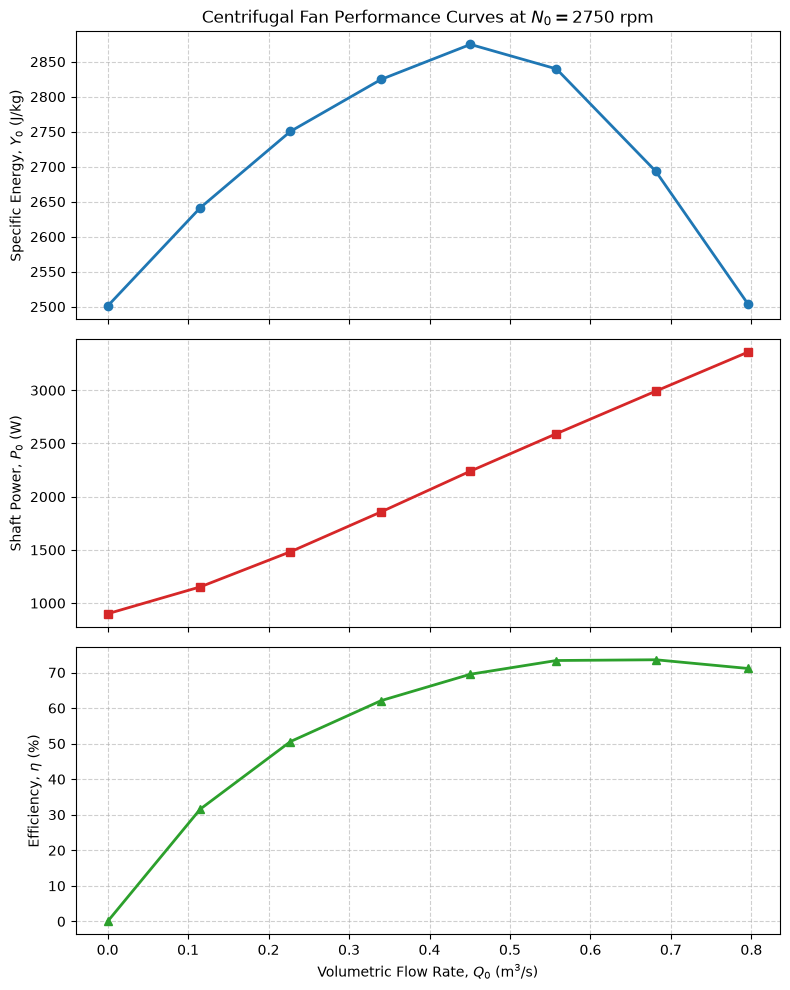

In [25]:
import matplotlib.pyplot as plt

# 1. Scale Q, Y, and P to the reference idling speed N0 = 2750 rpm
N0 = 2750.0
speed_ratio = N0 / exp_data['N (rpm)']

exp_data['Q_0 (m^3/s)'] = exp_data['Q (m^3/s)'] * speed_ratio
exp_data['Y_0 (J/kg)']  = exp_data['Y (J/kg)'] * (speed_ratio ** 2)
exp_data['P_0 (W)']     = exp_data['P (W)'] * (speed_ratio ** 3)

# 2. Specific speed Omega_s at the Best Efficiency Point (BEP)
bep = exp_data.loc[exp_data['eta'].idxmax()]
Omega_s = (bep['omega (rad/s)'] * np.sqrt(bep['Q (m^3/s)'])) / (bep['Y (J/kg)'] ** 0.75)

print(f"Best Efficiency Point (BEP): eta_max = {bep['eta']:.4f} at Q_0 = {bep['Q_0 (m^3/s)']:.4f} m^3/s")
print(f"Dimensionless Specific Speed at BEP: Omega_s = {Omega_s:.4f}")

# 3. Plot the Fan Performance Curves at N0 = 2750 rpm (using raw strings r'...' for LaTeX)
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

# Specific Energy Rise Y_0 vs Q_0
ax1.plot(exp_data['Q_0 (m^3/s)'], exp_data['Y_0 (J/kg)'], 'o-', color='tab:blue', linewidth=2)
ax1.set_ylabel(r'Specific Energy, $Y_0$ (J/kg)')
ax1.set_title(rf'Centrifugal Fan Performance Curves at $N_0 = {N0:.0f}$ rpm')
ax1.grid(True, linestyle='--', alpha=0.6)

# Shaft Power P_0 vs Q_0
ax2.plot(exp_data['Q_0 (m^3/s)'], exp_data['P_0 (W)'], 's-', color='tab:red', linewidth=2)
ax2.set_ylabel(r'Shaft Power, $P_0$ (W)')
ax2.grid(True, linestyle='--', alpha=0.6)

# Mechanical Efficiency eta vs Q_0
ax3.plot(exp_data['Q_0 (m^3/s)'], exp_data['eta'] * 100, '^-', color='tab:green', linewidth=2)
ax3.set_ylabel(r'Efficiency, $\eta$ (%)')
ax3.set_xlabel(r'Volumetric Flow Rate, $Q_0$ ($\mathrm{m^3/s}$)')
ax3.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

10. Plot performance curves $Y(Q)$, $P/Q)$ and $\eta(Q)$ and draw conclusions Use `matplotlib` with a code similar to this:
```python
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

exp_data.plot(x='Q_N (m^3/s)', y='Y_N (J/kg)', kind='line', marker='o', legend=False, ax=axes[0])
exp_data.plot(x='Q_N (m^3/s)', y='P_N (kW)', kind='line', marker='o', legend=False, ax=axes[1])
exp_data.plot(x='Q_N (m^3/s)', y='eta', kind='line', marker='o', legend=False, ax=axes[2])
axes[0].set_title('Fan performance curves for N = 2750 rpm')
axes[0].set_ylabel(r'$Y\,\text{(J/kg)}$')
axes[1].set_ylabel(r'$P\,\text{(kW)}$')
axes[2].set_xlabel(r'$Q\,\text{(m}^3\text{/s)}$')
axes[2].set_ylabel(r'$\eta$')
axes[2].set_ylim(0, 1)
for ax in axes:
    ax.grid()
plt.tight_layout()
```

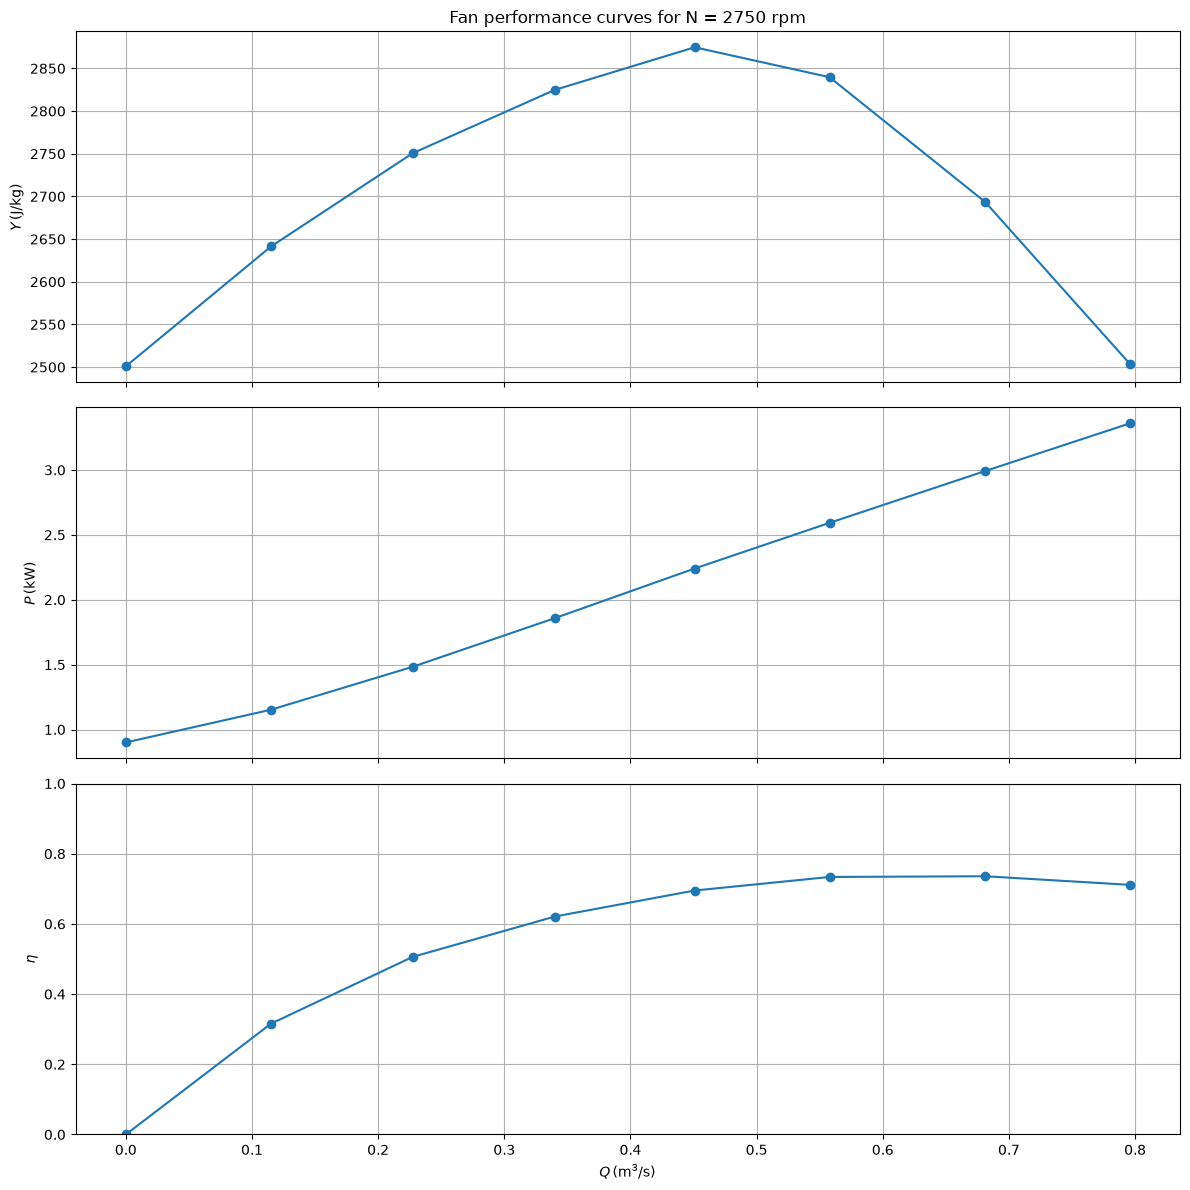

In [26]:
import matplotlib.pyplot as plt

# Ensure the DataFrame has the exact column names and kW units expected by the plot
exp_data['Q_N (m^3/s)'] = exp_data['Q_0 (m^3/s)']
exp_data['Y_N (J/kg)']  = exp_data['Y_0 (J/kg)']
exp_data['P_N (kW)']    = exp_data['P_0 (W)'] / 1000.0  # Convert W to kW

fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

exp_data.plot(x='Q_N (m^3/s)', y='Y_N (J/kg)', kind='line', marker='o', legend=False, ax=axes[0])
exp_data.plot(x='Q_N (m^3/s)', y='P_N (kW)', kind='line', marker='o', legend=False, ax=axes[1])
exp_data.plot(x='Q_N (m^3/s)', y='eta', kind='line', marker='o', legend=False, ax=axes[2])

axes[0].set_title('Fan performance curves for N = 2750 rpm')
axes[0].set_ylabel(r'$Y\,\mathrm{(J/kg)}$')
axes[1].set_ylabel(r'$P\,\mathrm{(kW)}$')
axes[2].set_xlabel(r'$Q\,\mathrm{(m}^3\mathrm{/s)}$')
axes[2].set_ylabel(r'$\eta$')
axes[2].set_ylim(0, 1)

for ax in axes:
    ax.grid()

plt.tight_layout()
plt.show()

## Your project

With respect to your project, consider the following points:
- According to the nominal flow rate of your axial fan, which flow rate device would be more convenient? In this example a ISA 1932 nozzle is used, but for larger flow rates, lower pressure, a different design could be more convenient. Perhaps a long-radius nozzle or a bellmouth inlet nozzle.
- Browse the catalogue by [Wika](https://www.wika.com/es-es/pagina_inicial.WIKA) or [Keller](https://keller-pressure.com) the suitable digital manometers for your application
- Look for the appropriate thermocouple for the measurement of temperature of air. See for instance [TC Direct](https://www.tcdirect.es/) or any other manufacturer/seller. Consider also how are you going to register the measurement. 

1. Flow Rate Measurement Device: Bellmouth Inlet Nozzle (ISO 5801 / AMCA 210)
    Installed at the inlet of a settling/plenum chamber (an ISO 5801 Type A chamber test rig), a bellmouth inlet nozzle accelerates ambient air smoothly from rest ($v_1 \approx 0$) into the throat with almost zero permanent head loss and a discharge coefficient $C_d \approx 0.98\text{–}0.99$ that is nearly independent of Reynolds number at high flow rates.
    
    For a $4.79\text{ m}^3/\text{s}$ max flow rate, selecting a bellmouth throat diameter around $d \approx 0.45\text{–}0.50\text{ m}$ yields a throat velocity of $24\text{–}30\text{ m/s}$ and a clean, easily measurable differential pressure drop of $\Delta p \approx 350\text{–}550\text{ Pa}$ at full flow without overloading the fan.

2. Suitable Digital Manometers (WIKA & KELLER)

    * WIKA | CPG1500 (Precision Digital Pressure Gauge) or CPH6200 / CPH7000 (Handheld Digital Manometer with differential pressure sensor). (High resolution ($0.1\text{–}1\text{ Pa}$) across the low pressure rise of the HCFB/4-630/H, plus onboard logging for steady-state point capture.)

    ![test_rig](images/E1_Manometer_CPG1500.jpg)

    * KELLER | LEO1 / LEO2 or LEO Ultimate (Digital Pressure Gauges) / PD-33X (High-Precision Differential Pressure Transmitter). (Swiss piezoresistive low-range sensors give high stability near zero pressure (free-delivery point) and direct PC readout via KELLER PressureSuite software.)

    ![test_rig](images/E1_Manometer_Leo1.webp)

3. Air Temperature Measurement & Data Registration (TC Direct)
    * TC DIRECT | Sensor de Propósito General tipo K (General Purpose Type K Thermocouple from TC Direct). Is a very practical, robust, and standard choice for a ventilation test bench.

    ![test_rig](images/E1_Termocouple_Type_K.png)
    

4. Data Acquisition & Wiring Best Practices
    Compensated Extension Cable: Always connect the probe to your logger using Type K compensated extension cable and miniature Type K connectors (green per IEC 60584-3) so you do not introduce parasitic junctions before the Cold Junction Compensation (CJC) sensor.Logging Setup: Connect both probes to a multi-channel USB thermocouple logger with built-in CJC (such as a Pico Technology / TC Direct TC-08, an NI 9211, or a handheld dual-channel logging thermometer with USB/CSV export) to log $T_a$ and $T$ directly into a CSV file for your pandas script.
